In [ ]:
# Name = Ritesh
# Roll no = 2601840023

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("Student_Performance.csv")

print("Dataset loaded successfully! First 5 rows:")
display(df.head())

Dataset loaded successfully! First 5 rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [ ]:
# --- STEP 2: DATA CLEANING & PREPROCESSING ---
print("Initial Shape:", df.shape)

# 1. Check & drop duplicate rows
df = df.drop_duplicates()

# 2. Check for missing values
print("\nMissing Values Count:\n", df.isnull().sum())

# 3. Rename columns for clean access
df.rename(columns={
    'Hours Studied': 'studytime',
    'Performance Index': 'final_score',
    'Previous Scores': 'previous_scores',
    'Sleep Hours': 'sleep_hours'
}, inplace=True)

print("\nCleaned Data Summary:")
display(df.describe())


Initial Shape: (10000, 6)

Missing Values Count:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Cleaned Data Summary:


,studytime,previous_scores,sleep_hours,Sample Question Papers Practiced,final_score
count,9987.000000,9987.000000,9987.000000,9987.000000,9987.000000
mean,4.993492,69.439271,6.529889,4.584760,55.361780
std,2.589062,17.339709,1.695880,2.867754,19.253851
min,1.000000,40.000000,4.000000,0.000000,10.100000
25%,3.000000,54.000000,5.000000,2.000000,40.300000
50%,5.000000,69.000000,7.000000,5.000000,55.300000
75%,7.000000,85.000000,8.000000,7.000000,70.700000
max,9.000000,99.000000,9.000000,9.000000,100.000000


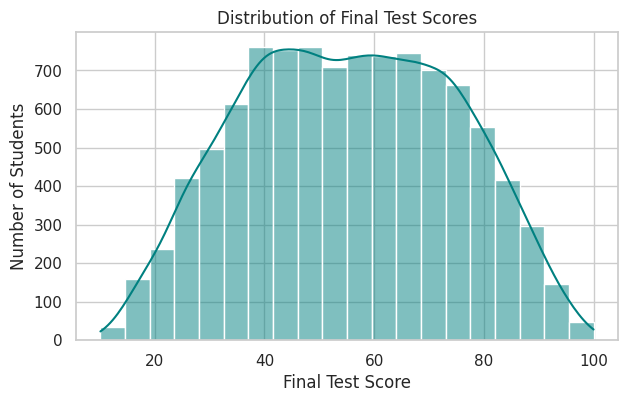

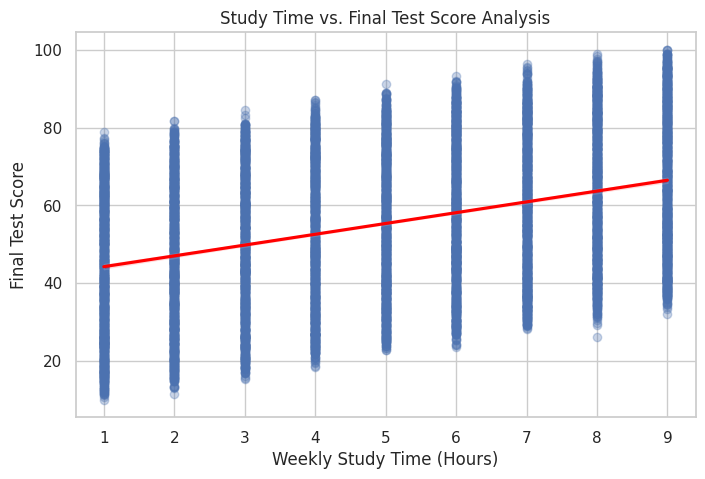

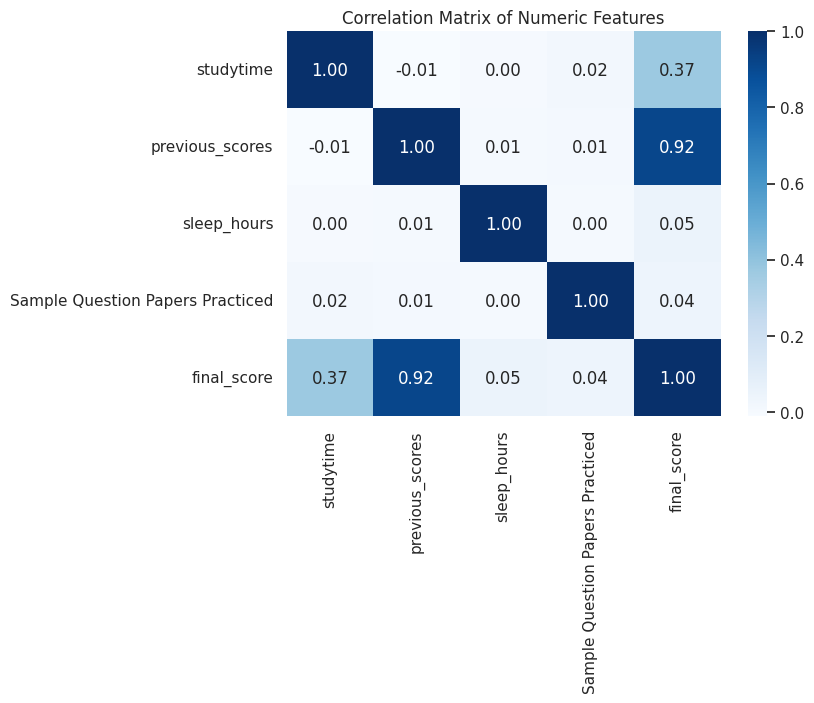

In [ ]:
# --- STEP 3: EXPLORATORY DATA ANALYSIS (EDA) ---
sns.set_theme(style="whitegrid")

# Graph 1: Distribution of Final Test Scores
plt.figure(figsize=(7, 4))
sns.histplot(df['final_score'], kde=True, color='teal', bins=20)
plt.title("Distribution of Final Test Scores", fontsize=12)
plt.xlabel("Final Test Score")
plt.ylabel("Number of Students")
plt.show()

# Graph 2: Scatter Plot with Trend Line (Study Time vs Final Score)
plt.figure(figsize=(8, 5))
sns.regplot(x='studytime', y='final_score', data=df, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Study Time vs. Final Test Score Analysis", fontsize=12)
plt.xlabel("Weekly Study Time (Hours)")
plt.ylabel("Final Test Score")
plt.show()

# Graph 3: Correlation Matrix
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Matrix of Numeric Features", fontsize=12)
plt.show()

In [ ]:
# --- STEP 4: STATISTICAL & ML ANALYSIS ---
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Spearman Correlation Analysis
rho, p_val = stats.spearmanr(df['studytime'], df['final_score'])
print(f"Spearman Correlation (Study Time vs Test Score): rho = {rho:.4f}, p-value = {p_val:.4e}")

# Baseline Linear Regression
X = df[['studytime', 'previous_scores', 'sleep_hours']]
y = df['final_score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Model R-squared (R2) Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")

Spearman Correlation (Study Time vs Test Score): rho = 0.3517, p-value = 1.3123e-288
Model R-squared (R2) Score: 0.9883
Mean Squared Error (MSE): 4.3127


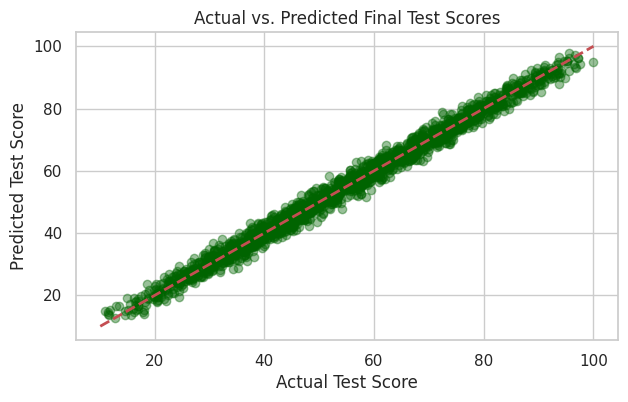

=== CAPSTONE CONCLUSION ===
1. Higher study time shows a positive correlation with final test scores.
2. Previous academic scores also heavily influence final test performance.
3. External factors (such as stress, teaching quality, and individual learning speed) are acknowledged limitations not captured in the dataset.


In [ ]:
# --- STEP 5: MODEL EVALUATION & CONCLUSION ---
plt.figure(figsize=(7, 4))
plt.scatter(y_test, y_pred, alpha=0.4, color='darkgreen')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title("Actual vs. Predicted Final Test Scores", fontsize=12)
plt.xlabel("Actual Test Score")
plt.ylabel("Predicted Test Score")
plt.show()

print("=== CAPSTONE CONCLUSION ===")
print("1. Higher study time shows a positive correlation with final test scores.")
print("2. Previous academic scores also heavily influence final test performance.")
print("3. External factors (such as stress, teaching quality, and individual learning speed) are acknowledged limitations not captured in the dataset.")